# C04a — ORG repetition controller

Step 9 targets the dominant residual FZ301 family observed after Step 8: `ner_ORG_*`.

The audit showed a strongly nonlinear detector response: **low ORG incidence is consistently AI-directed**, while high ORG values are generally human-directed. This notebook therefore treats low ORG incidence as the intervention direction and tests a narrow causal mechanism:

> When a sentence already contains one unambiguous spaCy `ORG` mention and later refers back to that organization without naming it, replace the later reference with the organization name.

Example:

`The FBI opened the inquiry, and it also contacted the agency.`

may produce a candidate such as:

`The FBI opened the inquiry, and FBI also contacted the agency.`

The controller is intentionally conservative:

- operate only when `ner_ORG_sentence_mean` is below the **same-genre fixed test-human median**;
- use only **same-sentence** antecedents;
- require exactly one distinct preceding ORG surface form for the reference;
- consider singular neutral pronouns (`it`, `its`) and a frozen list of generic organizational noun phrases;
- rank all proposals by a pinned causal-LM local likelihood delta;
- require the accepted edit to **strictly increase detected ORG sentence mean**;
- stop when the same-genre human median is reached, a bounded edit budget is exhausted, or no valid candidate remains.

This is a raw-feature intervention, not a detector-score search: FZ301 score/contributions are evaluated only after the text treatment is complete.

In [1]:
from pathlib import Path
import json, hashlib, pickle, re, math, warnings
from collections import Counter, defaultdict
from functools import lru_cache
import importlib.metadata as importlib_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy, textstat, sklearn
import torch
import torch.nn.functional as F

from sklearn.metrics import roc_curve, auc
from IPython.display import display
from transformers import AutoTokenizer, AutoModelForCausalLM

try:
    from empath import Empath
except ImportError as e:
    raise ImportError(
        "C04a needs `empath`, inherited from C04. "
        "Run `%pip install empath` once in this Jupyter kernel."
    ) from e

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
BASE = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid"
PRIOR = ROOT / "results/causal/C02e2_raid_feature_guided"
C04_ROOT = ROOT / "results/causal/C04_fz301_raid_fixed54"
LEX_ROOT = ROOT / "results/causal/C03e_lexical_micro_substitution"
FIG = ROOT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED = 20260911
B = 2000
normalize = lambda t: str(t).replace("\n", " ").replace("\r", " ")

nlp = spacy.load("en_core_web_sm")
empath = Empath()

features = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus = pd.read_parquet(BASE / "paired_corpus.parquet")
assert features.source_id.is_unique and corpus.source_id.is_unique
text_map = corpus.set_index("source_id").text.to_dict()
raid = features.loc[features.dataset.eq("raid")].copy().reset_index(drop=True)

# Resolve the accepted C04 detector by the results just observed.
c04_runs = []
for p in sorted(C04_ROOT.glob("*")):
    if not p.is_dir() or not (p / "FZ301.pkl").exists() or not (p / "stage_summary.csv").exists():
        continue
    s = pd.read_csv(p / "stage_summary.csv")
    if (
        len(s) == 3
        and np.isclose(float(s.iloc[0]["AUROC"]), 0.875380, atol=5e-6)
        and np.isclose(float(s.iloc[2]["AUROC"]), 0.699558, atol=5e-6)
    ):
        c04_runs.append(p)

assert len(c04_runs) == 1, (
    "Expected exactly one accepted C04 run matching the observed baseline; found:\n"
    + "\n".join(map(str, c04_runs))
)
C04_RUN = c04_runs[0]

c04_contract = json.loads((C04_RUN / "contract.json").read_text())
feature_manifest = json.loads((C04_RUN / "feature_manifest.json").read_text())
with (C04_RUN / "FZ301.pkl").open("rb") as f:
    fz301 = pickle.load(f)

POST8_PATH = ROOT / c04_contract["post8_file"]
post8 = pd.read_csv(POST8_PATH, keep_default_na=False).sort_values("case_id").reset_index(drop=True)
assert len(post8) == 54 and post8.case_id.is_unique and post8.source_id.is_unique
assert {"case_id", "source_id", "domain", "text"} <= set(post8.columns)

CACHE = (
    ROOT
    / "results/causal/C04_fz301_feature_cache"
    / c04_contract["feature_manifest_hash"]
)
assert (CACHE / "raid_extensions.parquet").exists()

human_test_manifest = pd.read_csv(C04_RUN / "human_test_manifest.csv")
human_cal_manifest = pd.read_csv(C04_RUN / "human_calibration_manifest.csv")

ORG_FEATURES = [
    "ner_ORG_entity_share",
    "ner_ORG_sentence_mean",
    "ner_ORG_sentence_std",
    "ner_ORG_sentence_max",
]

raid_ext_cache = pd.read_parquet(CACHE / "raid_extensions.parquet").set_index("source_id")
assert set(ORG_FEATURES) <= set(raid_ext_cache.columns)

human_org = raid_ext_cache.loc[human_test_manifest.source_id, ORG_FEATURES].copy()
human_org["domain"] = human_test_manifest.domain.to_numpy()

human_org_medians = human_org.groupby("domain")[ORG_FEATURES].median()
TARGET_FEATURE = "ner_ORG_sentence_mean"

print("Accepted C04 run:", C04_RUN.relative_to(ROOT))
print("Step-8 input:", POST8_PATH.relative_to(ROOT))
print("\nSame-genre human ORG medians:")
display(human_org_medians)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Accepted C04 run: results/causal/C04_fz301_raid_fixed54/d6c459f7c8a2
Step-8 input: results/causal/C03e_lexical_micro_substitution/60d5986e77d8/texts_after_lexical_scored.csv

Same-genre human ORG medians:


,ner_ORG_entity_share,ner_ORG_sentence_mean,ner_ORG_sentence_std,ner_ORG_sentence_max
domain,,,,
abstracts,0.400000,0.250000,0.433013,1.0
books,0.175192,0.436508,0.476565,1.0
news,0.176471,0.277778,0.489898,1.0
recipes,0.038462,0.052632,0.223297,1.0
reddit,0.000000,0.000000,0.000000,0.0
reviews,0.162500,0.170040,0.353408,1.0
wiki,0.192308,0.727273,0.799305,2.0


In [2]:
# Exact frozen project FZ118 extractor copied forward from C03.

PUNCTUATION = [
    ("comma", ","), ("period", "."), ("colon", ":"), ("semicolon", ";"),
    ("question", "?"), ("exclamation", "!"), ("hyphen", "-"), ("quote", '"'),
    ("lparen", "("), ("rparen", ")"), ("lbracket", "["), ("rbracket", "]"),
    ("newline", "\n"),
]

google_words = [
    w.strip().lower()
    for w in (BASE / "google-10000-english.txt").read_text().splitlines()
    if w.strip()
]
GOOGLE_TOP = {n: set(google_words[:n]) for n in [100, 1000, 10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0

def clean_word_tokens(span):
    return [token.text.lower() for token in span if token.is_alpha]

def clean_pos_tokens(span):
    return [token.pos_ for token in span if token.is_alpha]

def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(tuple(sequence[i:i+n]) for i in range(len(sequence) - n + 1))

def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    return float(sum((a & b).values()) / denominator)

def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)
    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))

def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(multiset_overlap(words[:i], words[i+1:], n))
    return float(np.mean(values)) if values else 0.0

def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)

def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0

def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

FEATURE_NAMES = json.loads((BASE / "fz118_feature_contract.json").read_text())["feature_names"]
assert len(FEATURE_NAMES) == 118

def fz118_frame(texts):
    arr = np.vstack([extract_fz118(t) for t in texts])
    return pd.DataFrame(arr, columns=FEATURE_NAMES)

# Sanity check against canonical stored RAID vectors.
# C04a does not define the C04 `original` stage table, so sample
# directly from the unchanged RAID rows.

check_rows = raid.iloc[:5].copy()

stored = (
    check_rows[
        FEATURE_NAMES
    ]
    .to_numpy(float)
)

recomputed = fz118_frame(
    [
        normalize(
            text_map[sid]
        )
        for sid in check_rows[
            "source_id"
        ]
    ]
).to_numpy(float)

np.testing.assert_allclose(
    recomputed,
    stored,
    atol=1e-9,
    rtol=0,
)

print(
    "✓ Exact FZ118 extractor "
    "sanity check passed."
)

✓ Exact FZ118 extractor sanity check passed.


In [3]:
# Freeze the project FZ301 v1 feature contract: 186 inherited + 115 new = 301.

POS_TAGS = [
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM",
    "PART", "PRON", "PROPN", "PUNCT", "SCONJ", "SYM", "VERB", "X"
]
POS_STATS = ["token_share", "sentence_mean", "sentence_std", "sentence_max"]
POS_NAMES = [f"pos_{tag}_{stat}" for tag in POS_TAGS for stat in POS_STATS]
assert len(POS_NAMES) == 68

NER_LABELS = list(nlp.get_pipe("ner").labels)
assert len(NER_LABELS) == 18, (
    f"Expected the frozen en_core_web_sm 18-label NER inventory, got {NER_LABELS}"
)
NER_STATS = ["entity_share", "sentence_mean", "sentence_std", "sentence_max"]
NER_NAMES = [f"ner_{label}_{stat}" for label in NER_LABELS for stat in NER_STATS]
assert len(NER_NAMES) == 72

COREF_NAMES = [
    "coref_mentions_per_sentence",
    "coref_clusters_per_sentence",
    "coref_repeated_clusters_per_sentence",
    "coref_repeated_cluster_share",
    "coref_repeated_mention_share",
    "coref_cluster_size_mean",
    "coref_cluster_size_std",
    "coref_cluster_size_max",
    "coref_distinct_sentence_mean",
    "coref_cross_sentence_cluster_share",
]
assert len(COREF_NAMES) == 10

GRID_ROLES = ["S", "O", "X", "-"]
GRID_NAMES = [f"entity_grid_{a}_{b}" for a in GRID_ROLES for b in GRID_ROLES]
assert len(GRID_NAMES) == 16

EMPATH_NAMES = [
    "empath_all_mean", "empath_all_median", "empath_all_min",
    "empath_all_max", "empath_all_var",
    "empath_active_mean", "empath_active_median", "empath_active_min",
    "empath_active_max", "empath_active_var",
    "empath_q10", "empath_q25", "empath_q75", "empath_q90",
    "empath_active_share",
]
assert len(EMPATH_NAMES) == 15

Q_NAMES = ["yule_q_mean"]
TOPIC_NAMES = ["topic_redundancy_mean_cosine"]

NEW115_NAMES = NER_NAMES + COREF_NAMES + GRID_NAMES + EMPATH_NAMES + Q_NAMES + TOPIC_NAMES
assert len(NEW115_NAMES) == 115 and len(set(NEW115_NAMES)) == 115

F186 = FEATURE_NAMES + POS_NAMES
F301 = F186 + NEW115_NAMES
assert len(F301) == 301 and len(set(F301)) == 301

EMPATH_CATS = sorted(empath.cats.keys())
assert len(EMPATH_CATS) >= 190

def pos_vector(doc):
    tokens = [t for t in doc if not t.is_space]
    assert {t.pos_ for t in tokens} <= set(POS_TAGS), "Unexpected POS label"
    counts = Counter(t.pos_ for t in tokens)
    sentences = [
        Counter(t.pos_ for t in s if not t.is_space)
        for s in doc.sents
        if any(not t.is_space for t in s)
    ]
    out = []
    for tag in POS_TAGS:
        a = np.asarray([s[tag] for s in sentences], dtype=float)
        out.extend([
            counts[tag] / max(len(tokens), 1),
            a.mean() if len(a) else 0.0,
            a.std(ddof=0) if len(a) else 0.0,
            a.max() if len(a) else 0.0,
        ])
    assert len(out) == 68
    return out

def ner_vector(doc):
    sentences = [s for s in doc.sents if any(not t.is_space for t in s)]
    ents = list(doc.ents)
    total_ents = len(ents)
    overall = Counter(e.label_ for e in ents)

    sent_counts = []
    for sent in sentences:
        c = Counter(
            ent.label_
            for ent in ents
            if ent.start >= sent.start and ent.end <= sent.end
        )
        sent_counts.append(c)

    out = []
    for label in NER_LABELS:
        a = np.asarray([c[label] for c in sent_counts], dtype=float)
        out.extend([
            overall[label] / max(total_ents, 1),
            a.mean() if len(a) else 0.0,
            a.std(ddof=0) if len(a) else 0.0,
            a.max() if len(a) else 0.0,
        ])
    assert len(out) == 72
    return out

def noun_chunk_key(span):
    # Identity-based proxy: remove determiners/stop words where possible and lemmatize.
    content = [
        t.lemma_.lower()
        for t in span
        if t.is_alpha and not t.is_stop and t.pos_ not in {"DET"}
    ]
    if not content:
        content = [t.lemma_.lower() for t in span if t.is_alpha]
    return " ".join(content).strip()

def grammatical_role(span):
    dep = span.root.dep_.lower()
    if dep in {"nsubj", "nsubjpass", "csubj", "csubjpass"}:
        return "S"
    if dep in {"obj", "dobj", "iobj", "pobj", "dative", "attr", "oprd"}:
        return "O"
    return "X"

def identity_mentions(doc):
    sentences = [s for s in doc.sents if any(not t.is_space for t in s)]
    token_to_sent = {}
    for j, sent in enumerate(sentences):
        for t in sent:
            token_to_sent[t.i] = j

    mentions = []
    for chunk in doc.noun_chunks:
        key = noun_chunk_key(chunk)
        if not key:
            continue
        sent_idx = token_to_sent.get(chunk.root.i)
        if sent_idx is None:
            continue
        mentions.append((key, sent_idx, grammatical_role(chunk)))
    return sentences, mentions

def coref_proxy_vector(doc):
    sentences, mentions = identity_mentions(doc)
    clusters = defaultdict(list)
    for key, sent_idx, role in mentions:
        clusters[key].append((sent_idx, role))

    sizes = np.asarray([len(v) for v in clusters.values()], dtype=float)
    repeated = [v for v in clusters.values() if len(v) > 1]
    repeated_mentions = sum(len(v) for v in repeated)
    distinct_sentence_counts = np.asarray(
        [len({s for s, _ in v}) for v in clusters.values()],
        dtype=float,
    )
    cross_sentence = sum(len({s for s, _ in v}) > 1 for v in clusters.values())

    ns = max(len(sentences), 1)
    nc = len(clusters)
    nm = len(mentions)

    out = [
        nm / ns,
        nc / ns,
        len(repeated) / ns,
        safe_div(len(repeated), nc),
        safe_div(repeated_mentions, nm),
        sizes.mean() if len(sizes) else 0.0,
        sizes.std(ddof=0) if len(sizes) else 0.0,
        sizes.max() if len(sizes) else 0.0,
        distinct_sentence_counts.mean() if len(distinct_sentence_counts) else 0.0,
        safe_div(cross_sentence, nc),
    ]
    assert len(out) == 10
    return out

def entity_grid_vector(doc):
    sentences, mentions = identity_mentions(doc)
    n_sent = len(sentences)
    keys = sorted({k for k, _, _ in mentions})
    if n_sent < 2 or not keys:
        return [0.0] * 16

    # If an identity has multiple mentions in one sentence, keep the strongest role.
    precedence = {"S": 3, "O": 2, "X": 1}
    roles = {k: ["-"] * n_sent for k in keys}
    for key, sent_idx, role in mentions:
        old = roles[key][sent_idx]
        if old == "-" or precedence[role] > precedence.get(old, 0):
            roles[key][sent_idx] = role

    counts = Counter()
    for key in keys:
        row = roles[key]
        for a, b in zip(row[:-1], row[1:]):
            counts[(a, b)] += 1

    total = sum(counts.values())
    out = [safe_div(counts[(a, b)], total) for a in GRID_ROLES for b in GRID_ROLES]
    assert len(out) == 16
    return out

def empath_vector(text):
    scores = empath.analyze(str(text), categories=EMPATH_CATS, normalize=True)
    vals = np.asarray([float(scores[c]) for c in EMPATH_CATS], dtype=float)
    active = vals[vals > 0]

    all_stats = [
        vals.mean(), np.median(vals), vals.min(), vals.max(), vals.var(ddof=0)
    ] if len(vals) else [0.0] * 5
    active_stats = [
        active.mean(), np.median(active), active.min(), active.max(), active.var(ddof=0)
    ] if len(active) else [0.0] * 5

    quantiles = (
        np.quantile(vals, [0.10, 0.25, 0.75, 0.90]).tolist()
        if len(vals) else [0.0] * 4
    )
    out = all_stats + active_stats + quantiles + [safe_div(len(active), len(vals))]
    assert len(out) == 15
    return out

def content_sentence_sets(doc):
    out = []
    for sent in doc.sents:
        s = {
            t.lemma_.lower()
            for t in sent
            if t.is_alpha and not t.is_stop and t.pos_ in {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}
        }
        if s:
            out.append(s)
    return out

def yule_q_mean(doc, max_terms=40):
    # Sentence-level Yule association over the most frequent content lemmas.
    sentence_sets = content_sentence_sets(doc)
    n = len(sentence_sets)
    if n < 2:
        return 0.0

    freq = Counter(w for s in sentence_sets for w in s)
    terms = [w for w, _ in sorted(freq.items(), key=lambda kv: (-kv[1], kv[0]))[:max_terms]]
    if len(terms) < 2:
        return 0.0

    present = {w: np.asarray([w in s for s in sentence_sets], dtype=bool) for w in terms}
    qs = []
    for i, a in enumerate(terms):
        A = present[a]
        for b in terms[i+1:]:
            B = present[b]
            n11 = int(np.sum(A & B))
            n10 = int(np.sum(A & ~B))
            n01 = int(np.sum(~A & B))
            n00 = int(np.sum(~A & ~B))
            den = n11 * n00 + n10 * n01
            if den:
                qs.append((n11 * n00 - n10 * n01) / den)
    return float(np.mean(qs)) if qs else 0.0

def topic_redundancy_mean_cosine(doc):
    # Pairwise cosine over sentence content-lemma count vectors.
    counters = []
    for sent in doc.sents:
        c = Counter(
            t.lemma_.lower()
            for t in sent
            if t.is_alpha and not t.is_stop and t.pos_ in {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}
        )
        if c:
            counters.append(c)

    if len(counters) < 2:
        return 0.0

    norms = [math.sqrt(sum(v * v for v in c.values())) for c in counters]
    sims = []
    for i, a in enumerate(counters):
        for j in range(i + 1, len(counters)):
            b = counters[j]
            dot = sum(v * b.get(k, 0) for k, v in a.items())
            denom = norms[i] * norms[j]
            sims.append(dot / denom if denom else 0.0)
    return float(np.mean(sims)) if sims else 0.0

def extension_vector(doc):
    out = (
        pos_vector(doc)
        + ner_vector(doc)
        + coref_proxy_vector(doc)
        + entity_grid_vector(doc)
        + empath_vector(doc.text)
        + [yule_q_mean(doc)]
        + [topic_redundancy_mean_cosine(doc)]
    )
    arr = np.asarray(out, dtype=np.float64)
    assert arr.shape == (183,)
    assert np.isfinite(arr).all()
    return arr

EXT_NAMES = POS_NAMES + NEW115_NAMES
assert len(EXT_NAMES) == 183

feature_manifest = {
    "name": "FZ301_project_v1",
    "source": (
        "Frozen project FZ186 v1 plus 115 C04 coordinates inspired by "
        "Fröhling & Zubiaga named-entity/coreference/entity-grid/Empath/Yule-Q families; "
        "not an exact original-paper reconstruction."
    ),
    "feature_names": F301,
    "blocks": {
        "FZ118": FEATURE_NAMES,
        "POS": POS_NAMES,
        "NER": NER_NAMES,
        "coreference_identity_proxy": COREF_NAMES,
        "entity_grid": GRID_NAMES,
        "Empath": EMPATH_NAMES,
        "Yule_Q": Q_NAMES,
        "topic_redundancy": TOPIC_NAMES,
    },
    "pos_tags": POS_TAGS,
    "pos_stats": POS_STATS,
    "ner_labels": NER_LABELS,
    "ner_stats": NER_STATS,
    "entity_grid_roles": GRID_ROLES,
    "coreference_policy": "identity-based normalized noun-chunk proxy; no neuralcoref",
    "empath_categories": EMPATH_CATS,
    "empath_policy": "default-category normalized scores summarized by 15 frozen statistics",
    "yule_q_policy": "mean sentence-level Yule Q over top-40 content lemmas by document frequency",
    "topic_redundancy_policy": "mean pairwise cosine of sentence content-lemma count vectors",
    "std_ddof": 0,
    "spacy": nlp.meta,
    "sklearn": sklearn.__version__,
    "empath_version": importlib_metadata.version("empath"),
}

manifest_hash = hashlib.sha256(
    json.dumps(feature_manifest, sort_keys=True, default=str).encode()
).hexdigest()[:12]

CACHE = ROOT / "results/causal/C04_fz301_feature_cache" / manifest_hash
CACHE.mkdir(parents=True, exist_ok=True)
(CACHE / "feature_manifest.json").write_text(json.dumps(feature_manifest, indent=2, default=str))

print("FZ301 manifest hash:", manifest_hash)
print("Feature counts:", {
    "FZ118": len(FEATURE_NAMES),
    "POS": len(POS_NAMES),
    "new_C04": len(NEW115_NAMES),
    "total": len(F301),
})

FZ301 manifest hash: 099d2763de75
Feature counts: {'FZ118': 118, 'POS': 68, 'new_C04': 115, 'total': 301}


In [4]:
# Pinned likelihood scorer + Step-9 contract.

# Recover the same scorer lineage used in the earlier controlled interventions.
scorer_candidates = [
    ROOT / "results/causal/C02r_discovery_gated_punctuation/treatment_contract.json",
]
scorer_candidates += sorted(LEX_ROOT.glob("*/contract.json"))

SCORER_ID = None
SCORER_REVISION = None
SCORER_SOURCE = None

for p in scorer_candidates:
    if not p.exists():
        continue
    try:
        j = json.loads(p.read_text())
    except Exception:
        continue

    sid = j.get("scorer")
    rev = j.get("scorer_revision", j.get("revision"))

    # Some contracts may store scorer metadata under config.
    if sid is None and isinstance(j.get("config"), dict):
        sid = j["config"].get("scorer")
        rev = rev or j["config"].get("scorer_revision") or j["config"].get("revision")

    if sid and rev and rev != "main":
        SCORER_ID = sid
        SCORER_REVISION = rev
        SCORER_SOURCE = p
        break

assert SCORER_ID and SCORER_REVISION, (
    "Could not recover a pinned scorer/revision from the existing intervention contracts."
)

STEP9_CFG = {
    "target_feature": TARGET_FEATURE,
    "target": "same-genre fixed test-human median",
    "same_sentence_only": True,
    "require_single_distinct_preceding_org_surface": False,
    "reference_types": [
        "it", "its", "they", "them", "their", "theirs",
        "generic_organization_np", "possessive_np",
    ],
    "left_words": 48,
    "right_words": 32,
    "min_local_mean_logp_delta": -2.0,
    "max_edits_per_case": 16,
    "max_candidates_per_step": 128,
    "seed": SEED,
}

contract = {
    "name": "C04a_ORG_repetition_controller_aggressive_v2",
    "config": STEP9_CFG,
    "parent_C04_run": str(C04_RUN.relative_to(ROOT)),
    "parent_C04_contract_sha256": hashlib.sha256((C04_RUN / "contract.json").read_bytes()).hexdigest(),
    "input_step8": str(POST8_PATH.relative_to(ROOT)),
    "input_step8_sha256": hashlib.sha256(POST8_PATH.read_bytes()).hexdigest(),
    "scorer": SCORER_ID,
    "scorer_revision": SCORER_REVISION,
    "scorer_contract": str(SCORER_SOURCE.relative_to(ROOT)),
    "spacy": nlp.meta,
    "torch": torch.__version__,
}

STEP9_HASH = hashlib.sha256(
    json.dumps(contract, sort_keys=True, default=str).encode()
).hexdigest()[:12]

OUT = ROOT / "results/causal/C04a_ORG_repetition" / STEP9_HASH
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "contract.json").write_text(json.dumps(contract, indent=2, default=str))

print("Step-9 output:", OUT.relative_to(ROOT))
print("Scorer:", SCORER_ID)
print("Revision:", SCORER_REVISION)
print("Scorer source:", SCORER_SOURCE.relative_to(ROOT))

tokenizer = AutoTokenizer.from_pretrained(
    SCORER_ID,
    revision=SCORER_REVISION,
    use_fast=True,
)
lm = AutoModelForCausalLM.from_pretrained(
    SCORER_ID,
    revision=SCORER_REVISION,
)
device = "cuda" if torch.cuda.is_available() else "cpu"
lm.to(device).eval()

model_ctx = getattr(lm.config, "max_position_embeddings", None)
if model_ctx is None:
    model_ctx = getattr(lm.config, "n_positions", None)
if model_ctx is None:
    model_ctx = tokenizer.model_max_length
if model_ctx is None or model_ctx > 100000:
    model_ctx = 1024

print("Likelihood device:", device, "| max context:", model_ctx)

Step-9 output: results/causal/C04a_ORG_repetition/a24eb48a893d
Scorer: gpt2
Revision: 607a30d783dfa663caf39e06633721c8d4cfcd7e
Scorer source: results/causal/C02r_discovery_gated_punctuation/treatment_contract.json


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 6531.47it/s]


Likelihood device: cuda | max context: 1024


In [5]:
# C04a Step 9 v2 — aggressive same-sentence ORG repetition controller.

WORD_RE = re.compile(r"\S+")


def org_stats(text):
    doc = nlp(str(text))

    sentences = [
        s
        for s in doc.sents
        if any(not t.is_space for t in s)
    ]

    ents = list(doc.ents)
    orgs = [e for e in ents if e.label_ == "ORG"]

    per_sentence = [
        sum(
            e.start >= sent.start
            and e.end <= sent.end
            for e in orgs
        )
        for sent in sentences
    ]

    a = np.asarray(per_sentence, dtype=float)

    return {
        "n_sentences": len(sentences),
        "n_entities": len(ents),
        "n_org": len(orgs),
        "ner_ORG_entity_share": safe_div(len(orgs), len(ents)),
        "ner_ORG_sentence_mean": a.mean() if len(a) else 0.0,
        "ner_ORG_sentence_std": a.std(ddof=0) if len(a) else 0.0,
        "ner_ORG_sentence_max": a.max() if len(a) else 0.0,
    }

GENERIC_ORG_HEADS = {
    "agency",
    "administration",
    "association",
    "bank",
    "board",
    "bureau",
    "business",
    "committee",
    "company",
    "corporation",
    "council",
    "department",
    "developer",
    "firm",
    "government",
    "group",
    "institution",
    "lab",
    "laboratory",
    "manufacturer",
    "network",
    "operator",
    "organization",
    "organisation",
    "party",
    "platform",
    "producer",
    "provider",
    "publisher",
    "retailer",
    "school",
    "team",
    "university",
}

PRONOUN_FORMS = {
    "it",
    "its",
    "they",
    "them",
    "their",
    "theirs",
}

ALLOWED_PRON_DEPS = {
    "nsubj",
    "nsubjpass",
    "obj",
    "dobj",
    "iobj",
    "pobj",
    "attr",
    "oprd",
    "poss",
}

ALLOWED_NP_DEPS = (
    ALLOWED_PRON_DEPS
    | {
        "appos",
        "conj",
        "obl",
        "nmod",
        "dative",
    }
)

def possessive_name(name):
    name = name.rstrip()

    return (
        name + "'"
        if name.lower().endswith("s")
        else name + "'s"
    )


def overlaps_any_entity(
    start,
    end,
    ents,
):
    return any(
        start < e.end_char
        and end > e.start_char
        for e in ents
    )


def preceding_orgs_in_sentence(
    orgs,
    sent,
    char_pos,
):

    return [
        e
        for e in orgs
        if (
            e.start >= sent.start
            and e.end <= sent.end
            and e.end_char <= char_pos
        )
    ]


def candidate_replacements_for_reference(
    orgs,
    sent,
    char_pos,
    reference_type,
):

    previous = (
        preceding_orgs_in_sentence(
            orgs,
            sent,
            char_pos,
        )
    )

    if not previous:
        return []

    # Nearest mention first, but KEEP every distinct preceding
    # organization surface. The LM will choose among them.
    previous = sorted(
        previous,
        key=lambda e: e.end_char,
        reverse=True,
    )

    seen = set()
    out = []

    for ent in previous:

        name = ent.text.strip()

        key = (
            re.sub(
                r"\s+",
                " ",
                name.lower(),
            )
        )

        if key in seen:
            continue

        seen.add(key)

        if reference_type in {
            "its",
            "their",
            "theirs",
            "possessive_np",
        }:
            replacement = (
                possessive_name(
                    name
                )
            )
        else:
            replacement = name

        out.append(
            {
                "org_name":
                    name,

                "replacement":
                    replacement,

                "antecedent_end":
                    ent.end_char,
            }
        )

    return out


def generate_org_reference_candidates(
    text,
):

    doc = nlp(
        str(text)
    )

    ents = list(
        doc.ents
    )

    orgs = [
        e
        for e in ents
        if e.label_ == "ORG"
    ]

    proposals = []
    seen = set()

    for sent_idx, sent in enumerate(
        doc.sents
    ):

        sent_orgs = [
            e
            for e in orgs
            if (
                e.start >= sent.start
                and e.end <= sent.end
            )
        ]

        if not sent_orgs:
            continue

        first_org_end = min(
            e.end_char
            for e in sent_orgs
        )

        # ----------------------------------------------------
        # Pronouns.
        # ----------------------------------------------------

        for tok in sent:

            low = tok.text.lower()

            if low not in PRONOUN_FORMS:
                continue

            if tok.idx <= first_org_end:
                continue

            if tok.dep_.lower() not in (
                ALLOWED_PRON_DEPS
            ):
                continue

            if tok.ent_type_:
                continue

            antecedents = (
                candidate_replacements_for_reference(
                    orgs,
                    sent,
                    tok.idx,
                    low,
                )
            )

            for ant in antecedents:

                key = (
                    tok.idx,
                    tok.idx + len(tok.text),
                    ant[
                        "replacement"
                    ],
                )

                if key in seen:
                    continue

                seen.add(key)

                proposals.append(
                    {
                        "sentence_index":
                            sent_idx,

                        "start":
                            tok.idx,

                        "end":
                            tok.idx
                            + len(
                                tok.text
                            ),

                        "reference":
                            tok.text,

                        "reference_type":
                            low,

                        "org_name":
                            ant[
                                "org_name"
                            ],

                        "replacement":
                            ant[
                                "replacement"
                            ],

                        "antecedent_distance_chars":
                            tok.idx
                            - ant[
                                "antecedent_end"
                            ],

                        "sentence":
                            sent.text.strip(),
                    }
                )


        # ----------------------------------------------------
        # Generic organizational noun phrases.
        # ----------------------------------------------------

        for chunk in doc.noun_chunks:

            if not (
                chunk.start
                >= sent.start
                and chunk.end
                <= sent.end
            ):
                continue

            if (
                chunk.start_char
                <= first_org_end
            ):
                continue

            head = (
                chunk.root
                .lemma_
                .lower()
            )

            if head not in (
                GENERIC_ORG_HEADS
            ):
                continue

            if (
                chunk.root.dep_.lower()
                not in ALLOWED_NP_DEPS
            ):
                continue

            # Don't rewrite an already recognized named entity.
            if overlaps_any_entity(
                chunk.start_char,
                chunk.end_char,
                ents,
            ):
                continue

            possessive = (
                chunk.root.dep_.lower()
                == "poss"
            )

            ref_type = (
                "possessive_np"
                if possessive
                else "generic_organization_np"
            )

            antecedents = (
                candidate_replacements_for_reference(
                    orgs,
                    sent,
                    chunk.start_char,
                    ref_type,
                )
            )

            for ant in antecedents:

                key = (
                    chunk.start_char,
                    chunk.end_char,
                    ant[
                        "replacement"
                    ],
                )

                if key in seen:
                    continue

                seen.add(key)

                proposals.append(
                    {
                        "sentence_index":
                            sent_idx,

                        "start":
                            chunk.start_char,

                        "end":
                            chunk.end_char,

                        "reference":
                            chunk.text,

                        "reference_type":
                            ref_type,

                        "org_name":
                            ant[
                                "org_name"
                            ],

                        "replacement":
                            ant[
                                "replacement"
                            ],

                        "antecedent_distance_chars":
                            chunk.start_char
                            - ant[
                                "antecedent_end"
                            ],

                        "sentence":
                            sent.text.strip(),
                    }
                )


    # Candidate enumeration itself is deterministic.
    proposals.sort(
        key=lambda q: (
            q[
                "sentence_index"
            ],
            q["start"],
            q[
                "antecedent_distance_chars"
            ],
            q[
                "replacement"
            ],
        )
    )

    return proposals

def local_window_pair(
    text,
    start,
    end,
    replacement,
    left_words=48,
    right_words=32,
):
    words = list(WORD_RE.finditer(text))

    left_candidates = [
        m for m in words
        if m.end() <= start
    ]

    right_candidates = [
        m for m in words
        if m.start() >= end
    ]

    if left_candidates:
        left_pick = left_candidates[
            max(0, len(left_candidates) - left_words)
        ]
        left_bound = left_pick.start()
    else:
        left_bound = max(0, start)

    if right_candidates:
        right_pick = right_candidates[
            min(len(right_candidates), right_words) - 1
        ]
        right_bound = right_pick.end()
    else:
        right_bound = end

    prefix = text[left_bound:start]
    suffix = text[end:right_bound]

    return (
        text[left_bound:right_bound],
        prefix + replacement + suffix,
    )


@lru_cache(maxsize=8192)
def mean_causal_logp(text):
    enc = tokenizer(
        text,
        return_tensors="pt",
        add_special_tokens=False,
    )

    ids = enc["input_ids"]

    if ids.shape[1] < 2:
        return float("-inf")

    if ids.shape[1] > model_ctx:
        return float("-inf")

    ids = ids.to(device)

    with torch.inference_mode():
        logits = lm(input_ids=ids).logits[:, :-1, :]
        targets = ids[:, 1:]

        token_lp = F.log_softmax(
            logits,
            dim=-1,
        ).gather(
            -1,
            targets.unsqueeze(-1),
        ).squeeze(-1)

    return float(token_lp.mean().item())


def score_proposal(text, proposal):
    original_window, candidate_window = local_window_pair(
        text,
        proposal["start"],
        proposal["end"],
        proposal["replacement"],
        STEP9_CFG["left_words"],
        STEP9_CFG["right_words"],
    )

    orig_lp = mean_causal_logp(original_window)
    cand_lp = mean_causal_logp(candidate_window)

    return (
        orig_lp,
        cand_lp,
        cand_lp - orig_lp,
    )


def apply_proposal(text, proposal):
    return (
        text[:proposal["start"]]
        + proposal["replacement"]
        + text[proposal["end"]:]
    )


print("✓ Aggressive ORG controller functions ready.")
print("Likelihood floor:", STEP9_CFG["min_local_mean_logp_delta"])
print("Max edits/case:", STEP9_CFG["max_edits_per_case"])
print("Max candidates/step:", STEP9_CFG["max_candidates_per_step"])

✓ Aggressive ORG controller functions ready.
Likelihood floor: -2.0
Max edits/case: 16
Max candidates/step: 128


In [6]:
# Run Step 9 over the 54 final Step-8 texts.

case_rows = []
edit_rows = []
proposal_rows = []

for case_num, row in enumerate(post8.itertuples(index=False), start=1):
    case_id = row.case_id
    domain = row.domain
    original_text = str(row.text)
    text = original_text

    target = float(human_org_medians.loc[domain, TARGET_FEATURE])
    before = org_stats(text)

    status = None
    n_edits = 0

    if before[TARGET_FEATURE] >= target - 1e-12:
        status = "already_at_or_above_median"
    else:
        while n_edits < STEP9_CFG["max_edits_per_case"]:
            current = org_stats(text)

            if current[TARGET_FEATURE] >= target - 1e-12:
                status = "reached_median"
                break

            proposals = generate_org_reference_candidates(text)

            if not proposals:
                status = (
                    "no_org_antecedent"
                    if current["n_org"] == 0
                    else "no_same_sentence_reference_candidate"
                )
                break

            proposals = proposals[:STEP9_CFG["max_candidates_per_step"]]

            scored = []
            for p in proposals:
                orig_lp, cand_lp, delta = score_proposal(text, p)
                q = dict(p)
                q.update({
                    "case_id": case_id,
                    "domain": domain,
                    "iteration": n_edits + 1,
                    "before_ORG_mean": current[TARGET_FEATURE],
                    "target_ORG_mean": target,
                    "original_local_mean_logp": orig_lp,
                    "candidate_local_mean_logp": cand_lp,
                    "likelihood_delta": delta,
                })
                scored.append(q)

            # Highest-likelihood candidate first; deterministic positional tiebreak.
            scored.sort(
                key=lambda q: (
                    -q["likelihood_delta"],
                    q["start"],
                    q["end"],
                    q["replacement"],
                )
            )

            accepted = None
            any_above_floor = False

            for rank, q in enumerate(scored, start=1):
                q["likelihood_rank"] = rank
                q["selected"] = False
                q["rejection_reason"] = ""

                if not np.isfinite(q["likelihood_delta"]):
                    q["rejection_reason"] = "nonfinite_likelihood"
                    proposal_rows.append(q)
                    continue

                if q["likelihood_delta"] < STEP9_CFG["min_local_mean_logp_delta"]:
                    q["rejection_reason"] = "below_likelihood_floor"
                    proposal_rows.append(q)
                    continue

                any_above_floor = True
                candidate_text = apply_proposal(text, q)
                after_try = org_stats(candidate_text)

                if after_try["n_sentences"] != current["n_sentences"]:
                    q["rejection_reason"] = "sentence_count_changed"
                    proposal_rows.append(q)
                    continue

                if after_try[TARGET_FEATURE] <= current[TARGET_FEATURE] + 1e-12:
                    q["rejection_reason"] = "did_not_increase_ORG_mean"
                    proposal_rows.append(q)
                    continue

                q["selected"] = True
                q["after_ORG_mean"] = after_try[TARGET_FEATURE]
                q["after_ORG_std"] = after_try["ner_ORG_sentence_std"]
                q["after_ORG_max"] = after_try["ner_ORG_sentence_max"]
                q["after_ORG_entity_share"] = after_try["ner_ORG_entity_share"]
                proposal_rows.append(q)

                accepted = (q, candidate_text, after_try)
                break

            if accepted is None:
                status = (
                    "all_candidates_below_likelihood_floor"
                    if not any_above_floor
                    else "no_candidate_increased_detected_ORG"
                )
                break

            q, new_text, after_try = accepted

            edit_rows.append({
                "case_id": case_id,
                "domain": domain,
                "edit_index": n_edits + 1,
                "sentence_index": q["sentence_index"],
                "reference_type": q["reference_type"],
                "reference": q["reference"],
                "org_name": q["org_name"],
                "replacement": q["replacement"],
                "likelihood_delta": q["likelihood_delta"],
                "before_ORG_mean": current[TARGET_FEATURE],
                "after_ORG_mean": after_try[TARGET_FEATURE],
                "target_ORG_mean": target,
                "sentence_before": q["sentence"],
            })

            text = new_text
            n_edits += 1

        if status is None:
            current = org_stats(text)
            status = (
                "reached_median"
                if current[TARGET_FEATURE] >= target - 1e-12
                else "max_edits_exhausted"
            )

    after = org_stats(text)

    case_rows.append({
        "case_id": case_id,
        "source_id": row.source_id,
        "domain": domain,
        "status": status,
        "n_edits": n_edits,
        "target_ORG_sentence_mean": target,
        "before_ORG_entity_share": before["ner_ORG_entity_share"],
        "after_ORG_entity_share": after["ner_ORG_entity_share"],
        "before_ORG_sentence_mean": before["ner_ORG_sentence_mean"],
        "after_ORG_sentence_mean": after["ner_ORG_sentence_mean"],
        "before_ORG_sentence_std": before["ner_ORG_sentence_std"],
        "after_ORG_sentence_std": after["ner_ORG_sentence_std"],
        "before_ORG_sentence_max": before["ner_ORG_sentence_max"],
        "after_ORG_sentence_max": after["ner_ORG_sentence_max"],
        "before_n_ORG": before["n_org"],
        "after_n_ORG": after["n_org"],
        "reached_median": after[TARGET_FEATURE] >= target - 1e-12,
        "text_before": original_text,
        "text": text,
    })

    if case_num % 10 == 0 or case_num == len(post8):
        print(f"Processed {case_num}/{len(post8)}")

step9_cases = pd.DataFrame(case_rows)
step9_edits = pd.DataFrame(edit_rows)
step9_proposals = pd.DataFrame(proposal_rows)

assert len(step9_cases) == 54 and step9_cases.case_id.is_unique
assert step9_cases[["case_id", "source_id", "domain"]].equals(
    post8[["case_id", "source_id", "domain"]]
)

step9_cases.to_csv(OUT / "texts_after_ORG_step9.csv", index=False)
step9_edits.to_csv(OUT / "edit_log.csv", index=False)
step9_proposals.to_csv(OUT / "proposal_audit.csv", index=False)

print("\nStatus counts:")
display(step9_cases.status.value_counts().rename_axis("status").to_frame("n"))

print("Edited cases:", int((step9_cases.n_edits > 0).sum()), "/ 54")
print("Total edits:", int(step9_cases.n_edits.sum()))
print(
    "At/above same-genre ORG-mean median before:",
    int((step9_cases.before_ORG_sentence_mean >= step9_cases.target_ORG_sentence_mean - 1e-12).sum()),
    "/ 54",
)
print(
    "At/above same-genre ORG-mean median after:",
    int(step9_cases.reached_median.sum()),
    "/ 54",
)

display(
    step9_cases[
        [
            "case_id", "domain", "status", "n_edits",
            "target_ORG_sentence_mean",
            "before_ORG_sentence_mean", "after_ORG_sentence_mean",
            "before_ORG_sentence_std", "after_ORG_sentence_std",
            "before_ORG_sentence_max", "after_ORG_sentence_max",
        ]
    ].sort_values(["n_edits", "case_id"], ascending=[False, True]).head(30)
)

if len(step9_edits):
    print("\nAccepted edits:")
    display(step9_edits)

Processed 10/54
Processed 20/54
Processed 30/54
Processed 40/54
Processed 50/54
Processed 54/54

Status counts:


,n
status,
already_at_or_above_median,28
no_org_antecedent,14
no_same_sentence_reference_candidate,9
reached_median,3


Edited cases: 3 / 54
Total edits: 5
At/above same-genre ORG-mean median before: 28 / 54
At/above same-genre ORG-mean median after: 31 / 54


,case_id,domain,status,n_edits,target_ORG_sentence_mean,before_ORG_sentence_mean,after_ORG_sentence_mean,before_ORG_sentence_std,after_ORG_sentence_std,before_ORG_sentence_max,after_ORG_sentence_max
29,gate_0051,wiki,reached_median,2,0.727273,0.545455,0.727273,0.782030,1.135454,2.0,3.0
44,gate_0082,wiki,reached_median,2,0.727273,0.600000,0.800000,0.663325,0.871780,2.0,2.0
46,gate_0086,wiki,reached_median,1,0.727273,0.636364,0.727273,0.881396,1.052349,2.0,3.0
0,gate_0001,abstracts,no_org_antecedent,0,0.250000,0.000000,0.000000,0.000000,0.000000,0.0,0.0
1,gate_0003,news,no_org_antecedent,0,0.277778,0.000000,0.000000,0.000000,0.000000,0.0,0.0
2,gate_0004,recipes,already_at_or_above_median,0,0.052632,0.052632,0.052632,0.223297,0.223297,1.0,1.0
3,gate_0005,reddit,already_at_or_above_median,0,0.000000,0.142857,0.142857,0.349927,0.349927,1.0,1.0
4,gate_0007,wiki,no_same_sentence_reference_candidate,0,0.727273,0.666667,0.666667,0.699206,0.699206,2.0,2.0
5,gate_0015,abstracts,already_at_or_above_median,0,0.250000,0.250000,0.250000,0.433013,0.433013,1.0,1.0
6,gate_0016,books,no_org_antecedent,0,0.436508,0.000000,0.000000,0.000000,0.000000,0.0,0.0



Accepted edits:


,case_id,domain,edit_index,sentence_index,reference_type,reference,org_name,replacement,likelihood_delta,before_ORG_mean,after_ORG_mean,target_ORG_mean,sentence_before
0,gate_0051,wiki,1,3,their,their,Blue Merle,Blue Merle's,0.061639,0.545455,0.636364,0.727273,Liam and Caleb Finn formed Blue Merle in two t...
1,gate_0051,wiki,2,10,its,its,Blue Merle,Blue Merle's,0.019178,0.636364,0.727273,0.727273,In a two thousand fourteen interview with The ...
2,gate_0082,wiki,1,2,its,its,Grasser,Grasser's,-0.060299,0.600000,0.700000,0.727273,Grasser's music is characterized by its use of...
3,gate_0082,wiki,2,7,its,its,Grasser,Grasser's,-0.099131,0.700000,0.800000,0.727273,Grasser's music has been praised for its emoti...
4,gate_0086,wiki,1,1,generic_organization_np,the party,Knesset,Knesset,0.089019,0.636364,0.727273,0.727273,He previously held the post of Knesset member ...


Step 9: 50/54
Step 9: 54/54
Frozen FZ301 before/after Step 9:


,stage,AUROC,mean_AI_score,median_AI_score,AUROC_change_vs_step8,mean_score_change_vs_step8
0,Post Step 8,0.699558,0.500605,0.478403,0.000000,0.000000
1,Post Step 9 ORG,0.698396,0.500061,0.478403,-0.001163,-0.000544


Score decreased on: 13 / 54


,case_id,source_id,domain,status,n_edits,post_step8_AI_score,post_step9_AI_score,score_change
44,gate_0082,ai__raid:9f6e6f4d-9b87-449c-8ad4-740ec0b34368,wiki,reached_median,2,0.520274,0.505901,-1.437302e-02
46,gate_0086,ai__raid:7ced28f5-df4d-40ba-a6f1-e7fa8fbb9640,wiki,reached_median,1,0.422048,0.412203,-9.845238e-03
29,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,wiki,reached_median,2,0.458288,0.453121,-5.166667e-03
37,gate_0073,ai__raid:c9d4b9c3-20c6-4527-8838-6cbc2263bb00,wiki,no_org_antecedent,0,0.479841,0.479841,-2.220446e-16
45,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes,already_at_or_above_median,0,0.525647,0.525647,-2.220446e-16
20,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books,no_org_antecedent,0,0.574587,0.574587,-1.110223e-16
30,gate_0054,ai__raid:8598c9e2-8e28-46b2-a6da-a22b767aae49,news,no_same_sentence_reference_candidate,0,0.448327,0.448327,-1.110223e-16
51,gate_0093,ai__raid:6cb1edfa-92ac-4618-9084-7d84a4193bc4,news,no_org_antecedent,0,0.455252,0.455252,-1.110223e-16
19,gate_0030,ai__raid:fcc95fec-43c3-4885-86f5-8e310a8d552f,news,no_same_sentence_reference_candidate,0,0.436675,0.436675,-5.551115e-17
50,gate_0092,ai__raid:b146a6b9-b531-4709-ac99-6a3852b3c619,abstracts,already_at_or_above_median,0,0.310622,0.310622,-5.551115e-17


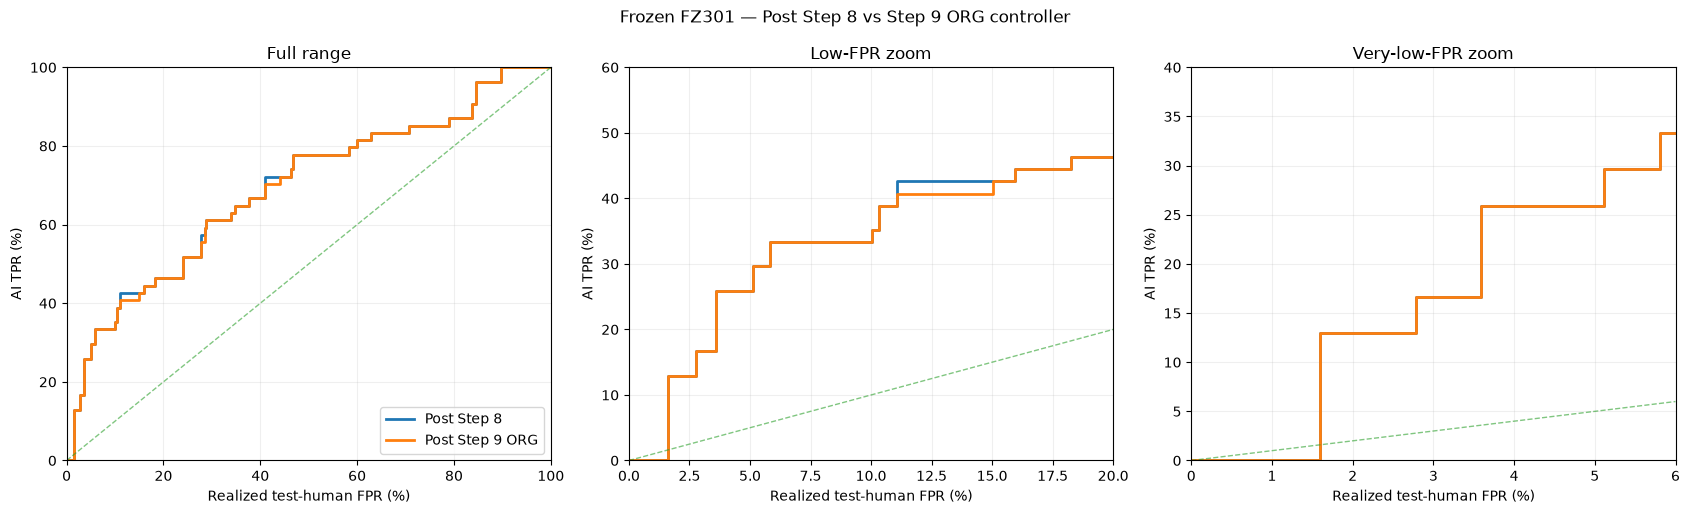

In [7]:
# Recompute all 301 coordinates after Step 9 and evaluate the frozen FZ301 detector.
# This is deliberately after treatment; detector score was not used for candidate selection.

def extension_frame(texts, desc="texts", batch_size=64):
    rows = []
    texts = list(map(str, texts))
    for i, doc in enumerate(nlp.pipe(texts, batch_size=batch_size)):
        rows.append(extension_vector(doc))
        if (i + 1) % 50 == 0 or i + 1 == len(texts):
            print(f"{desc}: {i+1}/{len(texts)}")
    return pd.DataFrame(np.vstack(rows), columns=EXT_NAMES)

F301 = list(feature_manifest["feature_names"])
assert len(F301) == 301
assert list(fz301.feature_names_in_) == F301

# Exact Post-Step-8 matrix saved by C04.
before_files = sorted(C04_RUN.glob("*post_step_8_features.csv"))
assert len(before_files) == 1, before_files
X_before = pd.read_csv(before_files[0]).set_index("case_id").loc[step9_cases.case_id, F301].reset_index(drop=True)

after_118 = fz118_frame(step9_cases.text.tolist())
after_ext = extension_frame(step9_cases.text.tolist(), desc="Step 9")
X_after = pd.concat([after_118, after_ext], axis=1)[F301]
assert X_after.shape == (54, 301)
assert np.isfinite(X_after.to_numpy(float)).all()

# Reconstruct all RAID FZ301 coordinates from the C04 cache for humans.
raid_ext = (
    pd.read_parquet(CACHE / "raid_extensions.parquet")
    .set_index("source_id")
    .loc[raid.source_id, EXT_NAMES]
    .reset_index(drop=True)
)
XR = pd.concat([raid[FEATURE_NAMES].reset_index(drop=True), raid_ext], axis=1)[F301]
assert XR.shape[0] == len(raid)

mix = step9_cases.domain.value_counts(normalize=True)

def human_mask(split):
    return (
        raid.split.eq(split)
        & raid.label.eq(0)
        & raid.domain.isin(mix.index)
    ).to_numpy()

calmask = human_mask("validation")
hmask = human_mask("test")

def genre_weights(mask):
    g = raid.loc[mask, "domain"]
    counts = g.value_counts()
    w = np.asarray([mix[x] / counts[x] for x in g], dtype=float)
    assert np.isclose(w.sum(), 1.0)
    return w

wc = genre_weights(calmask)
wh = genre_weights(hmask)

cal_scores = fz301.predict_proba(XR.loc[calmask, F301])[:, 1]
human_scores = fz301.predict_proba(XR.loc[hmask, F301])[:, 1]
before_scores = fz301.predict_proba(X_before[F301])[:, 1]
after_scores = fz301.predict_proba(X_after[F301])[:, 1]

def weighted_auc(ai_scores):
    fpr, tpr, _ = roc_curve(
        np.r_[np.zeros(len(human_scores)), np.ones(len(ai_scores))],
        np.r_[human_scores, ai_scores],
        sample_weight=np.r_[wh, np.ones(len(ai_scores)) / len(ai_scores)],
        drop_intermediate=False,
    )
    return auc(fpr, tpr)

eval_summary = pd.DataFrame([
    {
        "stage": "Post Step 8",
        "AUROC": weighted_auc(before_scores),
        "mean_AI_score": before_scores.mean(),
        "median_AI_score": np.median(before_scores),
    },
    {
        "stage": "Post Step 9 ORG",
        "AUROC": weighted_auc(after_scores),
        "mean_AI_score": after_scores.mean(),
        "median_AI_score": np.median(after_scores),
    },
])
eval_summary["AUROC_change_vs_step8"] = eval_summary.AUROC - eval_summary.iloc[0].AUROC
eval_summary["mean_score_change_vs_step8"] = eval_summary.mean_AI_score - eval_summary.iloc[0].mean_AI_score
eval_summary.to_csv(OUT / "evaluation_summary.csv", index=False)

print("Frozen FZ301 before/after Step 9:")
display(eval_summary)

case_scores = step9_cases[
    ["case_id", "source_id", "domain", "status", "n_edits"]
].copy()
case_scores["post_step8_AI_score"] = before_scores
case_scores["post_step9_AI_score"] = after_scores
case_scores["score_change"] = after_scores - before_scores
case_scores.to_csv(OUT / "case_scores.csv", index=False)

print(
    "Score decreased on:",
    int((case_scores.score_change < 0).sum()),
    "/ 54",
)
display(case_scores.sort_values("score_change").head(20))

# Detailed calibration-threshold staircase: same frozen detector, hence same thresholds.
cuts = np.r_[np.inf, np.unique(cal_scores)[::-1], -np.inf]
stair = pd.DataFrame({
    "threshold": cuts,
    "calibration_FPR": [wc[cal_scores > c].sum() for c in cuts],
    "test_FPR": [wh[human_scores > c].sum() for c in cuts],
    "Post Step 8": [(before_scores > c).mean() for c in cuts],
    "Post Step 9 ORG": [(after_scores > c).mean() for c in cuts],
})
stair.to_csv(OUT / "detailed_TPR_staircase.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
panels = [
    ((0, 100), (0, 100), "Full range"),
    ((0, 20), (0, 60), "Low-FPR zoom"),
    ((0, 6), (0, 40), "Very-low-FPR zoom"),
]

for ax, (xlim, ylim, title) in zip(axs, panels):
    for label in ["Post Step 8", "Post Step 9 ORG"]:
        ax.step(
            stair.test_FPR * 100,
            stair[label] * 100,
            where="post",
            linewidth=2,
            label=label,
        )
    hi = min(xlim[1], ylim[1])
    ax.plot([0, hi], [0, hi], "--", linewidth=1, alpha=0.6)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel("Realized test-human FPR (%)")
    ax.set_ylabel("AI TPR (%)")
    ax.set_title(title)
    ax.grid(alpha=0.2)

axs[0].legend(loc="lower right")
fig.suptitle("Frozen FZ301 — Post Step 8 vs Step 9 ORG controller")
fig.tight_layout()

for folder in [OUT, FIG]:
    fig.savefig(folder / "C04a_FZ301_step8_vs_step9_ORG_TPR_staircase.pdf", bbox_inches="tight")
    fig.savefig(folder / "C04a_FZ301_step8_vs_step9_ORG_TPR_staircase.png", dpi=220, bbox_inches="tight")
plt.show()

In [8]:
# Contribution check: did the ORG family move in the intended direction, and what remains?

def forest_contributions(model, frame):
    X = np.asarray(frame, dtype=np.float32)
    output = np.zeros_like(X, dtype=float)
    bias = 0.0

    for estimator in model.estimators_:
        tree = estimator.tree_
        value = tree.value[:, 0, :].astype(float)
        prob = value[:, 1] / value.sum(axis=1)
        bias += prob[0] / len(model.estimators_)

        for i, row in enumerate(X):
            node = 0
            while tree.children_left[node] != tree.children_right[node]:
                feature = tree.feature[node]
                child = (
                    tree.children_left[node]
                    if row[feature] <= tree.threshold[node]
                    else tree.children_right[node]
                )
                output[i, feature] += (
                    prob[child] - prob[node]
                ) / len(model.estimators_)
                node = child

    np.testing.assert_allclose(
        bias + output.sum(axis=1),
        model.predict_proba(frame)[:, 1],
        atol=1e-8,
        rtol=0,
    )
    return output

before_contrib = forest_contributions(fz301, X_before[F301])
after_contrib = forest_contributions(fz301, X_after[F301])
human_contrib = forest_contributions(fz301, XR.loc[hmask, F301])

human_ref = (
    pd.DataFrame(human_contrib, columns=F301)
    .assign(domain=raid.loc[hmask, "domain"].to_numpy())
    .groupby("domain")[F301]
    .mean()
)

ref = human_ref.loc[step9_cases.domain].to_numpy()
before_gap = before_contrib - ref
after_gap = after_contrib - ref

org_compare = []
for f in ORG_FEATURES:
    j = F301.index(f)
    org_compare.append({
        "feature": f,
        "Step8_gap": before_gap[:, j].mean(),
        "Step9_gap": after_gap[:, j].mean(),
        "change": after_gap[:, j].mean() - before_gap[:, j].mean(),
        "Step8_fraction_AI_directed": (before_gap[:, j] > 0).mean(),
        "Step9_fraction_AI_directed": (after_gap[:, j] > 0).mean(),
    })

org_compare = pd.DataFrame(org_compare)
org_compare.to_csv(OUT / "ORG_contribution_before_after.csv", index=False)
print("ORG contribution movement:")
display(org_compare)

# Bootstrap final Step-9 human-adjusted gaps for ranking.
rng = np.random.default_rng(SEED)
boot = np.zeros((B, len(F301)), dtype=float)
for domain in sorted(mix.index):
    ix = np.flatnonzero(step9_cases.domain.to_numpy() == domain)
    draw = rng.choice(ix, size=(B, len(ix)), replace=True)
    boot += (len(ix) / 54.0) * after_gap[draw].mean(axis=1)

lo, hi = np.quantile(boot, [0.025, 0.975], axis=0)

remaining = pd.DataFrame({
    "feature": F301,
    "human_adjusted_gap": after_gap.mean(axis=0),
    "ci_low": lo,
    "ci_high": hi,
    "fraction_AI_directed": (after_gap > 0).mean(axis=0),
}).sort_values("human_adjusted_gap", ascending=False).reset_index(drop=True)

remaining.to_csv(OUT / "post_step9_remaining_contributions.csv", index=False)

print("\nTop 30 remaining after Step 9:")
display(remaining.head(30))

ORG contribution movement:


,feature,Step8_gap,Step9_gap,change,Step8_fraction_AI_directed,Step9_fraction_AI_directed
0,ner_ORG_entity_share,0.000600,0.000565,-0.000035,0.500000,0.481481
1,ner_ORG_sentence_mean,0.002614,0.002580,-0.000034,0.648148,0.648148
2,ner_ORG_sentence_std,0.002801,0.002682,-0.000119,0.611111,0.592593
3,ner_ORG_sentence_max,0.002142,0.002059,-0.000083,0.592593,0.574074



Top 30 remaining after Step 9:


,feature,human_adjusted_gap,ci_low,ci_high,fraction_AI_directed
0,ner_ORG_sentence_std,0.002682,0.000992,0.004547,0.592593
1,ner_ORG_sentence_mean,0.002580,0.000945,0.004318,0.648148
2,ner_CARDINAL_sentence_max,0.002282,0.000996,0.003506,0.648148
3,share_unique_words,0.002140,0.000318,0.004140,0.462963
4,ner_ORG_sentence_max,0.002059,0.000547,0.003591,0.574074
5,pos_ADV_sentence_max,0.001998,0.000880,0.003171,0.611111
6,ner_PERSON_sentence_mean,0.001947,0.001013,0.002747,0.722222
7,ner_CARDINAL_sentence_std,0.001796,0.000653,0.002897,0.629630
8,ner_CARDINAL_entity_share,0.001655,0.000242,0.002975,0.629630
9,ner_CARDINAL_sentence_mean,0.001648,0.000512,0.002799,0.666667


Top 30 remaining contributions after Step 9:


,feature,Step8_gap,Step9_gap,Step9_minus_Step8,Step9_ci_low,Step9_ci_high
0,ner_ORG_sentence_std,0.002801,0.002682,-0.000119,0.000992,0.004547
1,ner_ORG_sentence_mean,0.002614,0.002580,-0.000034,0.000945,0.004318
2,ner_CARDINAL_sentence_max,0.002307,0.002282,-0.000025,0.000996,0.003506
3,share_unique_words,0.002104,0.002140,0.000036,0.000318,0.004140
4,ner_ORG_sentence_max,0.002142,0.002059,-0.000083,0.000547,0.003591
5,pos_ADV_sentence_max,0.002016,0.001998,-0.000017,0.000880,0.003171
6,ner_PERSON_sentence_mean,0.001980,0.001947,-0.000033,0.001013,0.002747
7,ner_CARDINAL_sentence_std,0.001798,0.001796,-0.000002,0.000653,0.002897
8,ner_CARDINAL_entity_share,0.001643,0.001655,0.000012,0.000242,0.002975
9,ner_CARDINAL_sentence_mean,0.001630,0.001648,0.000018,0.000512,0.002799



Largest contribution changes caused by Step 9:


,feature,Step8_gap,Step9_gap,Step9_minus_Step8
0,pos_2gram_overlap_bin_1,0.000087,0.000252,0.000165
1,ner_ORG_sentence_std,0.002801,0.002682,-0.000119
2,pos_PART_sentence_max,0.000148,0.000039,-0.000109
3,pos_PART_sentence_std,0.000286,0.000191,-0.000096
4,word_2gram_overlap_bin_1,0.000150,0.000063,-0.000087
5,ner_ORG_sentence_max,0.002142,0.002059,-0.000083
6,share_google_top10000,0.001659,0.001576,-0.000082
7,pos_NUM_sentence_mean,0.000717,0.000792,0.000075
8,share_google_top100,-0.000276,-0.000342,-0.000065
9,ner_DATE_sentence_std,0.000279,0.000344,0.000065


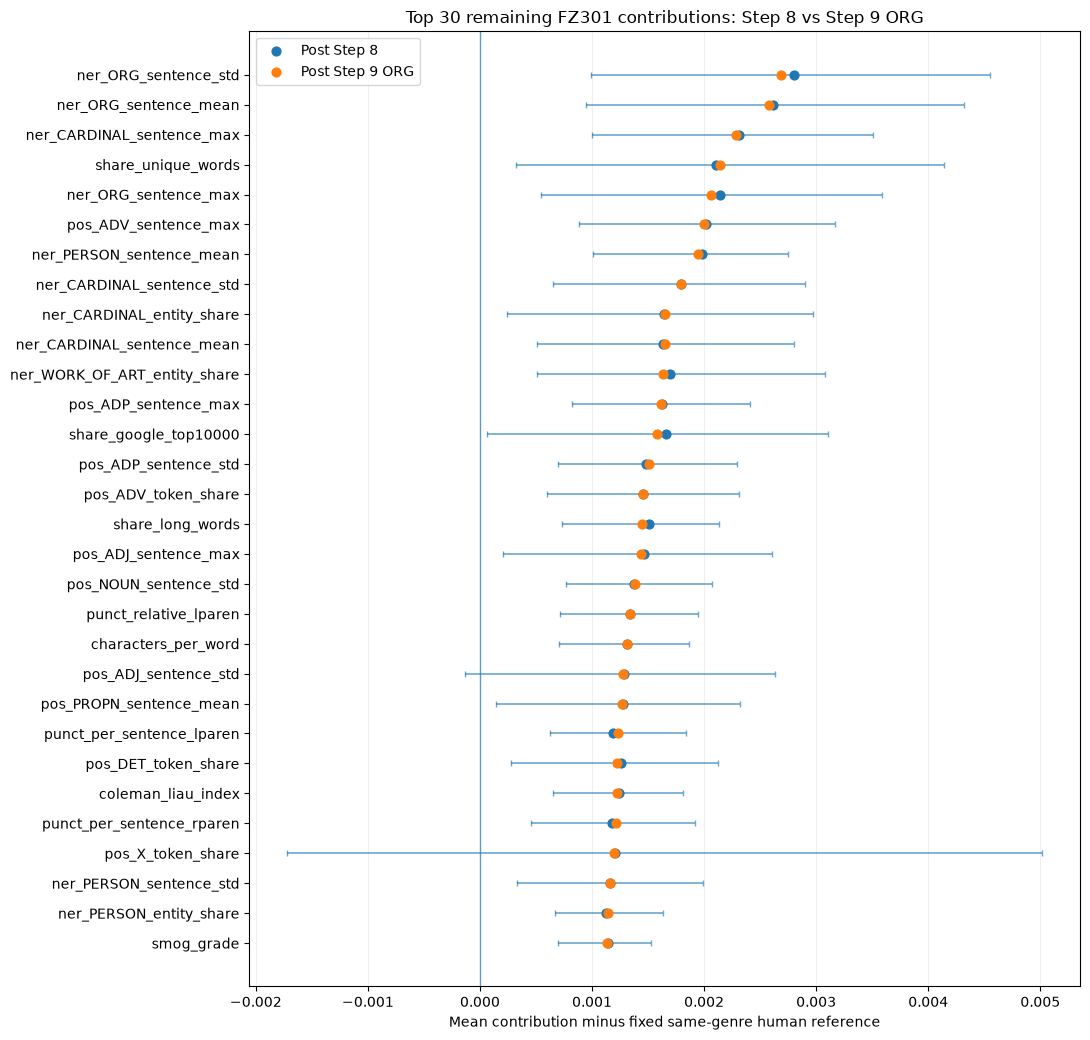

In [9]:
# C04a — contribution comparison:
# Post Step 8 vs Post Step 9 ORG controller.
#
# Ranks features by current (Step-9) human-adjusted contribution gap.
# Gray interval = 95% bootstrap CI for Step 9.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# Requires the previous contribution-analysis cell.
# ------------------------------------------------------------

required = [
    "before_gap",
    "after_gap",
    "F301",
    "step9_cases",
]

missing = [
    x
    for x in required
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Run the contribution-analysis cell first. "
        f"Missing: {missing}"
    )


# ------------------------------------------------------------
# Mean human-adjusted contribution before / after.
# ------------------------------------------------------------

step8_gap_mean = (
    before_gap.mean(axis=0)
)

step9_gap_mean = (
    after_gap.mean(axis=0)
)


# ------------------------------------------------------------
# Genre-stratified bootstrap CI for CURRENT Step 9.
# ------------------------------------------------------------

rng = np.random.default_rng(
    SEED
)

B_COMPARE = 2000

boot = np.zeros(
    (
        B_COMPARE,
        len(F301),
    ),
    dtype=float,
)

domains = (
    step9_cases[
        "domain"
    ]
    .to_numpy()
)

for domain in sorted(
    step9_cases[
        "domain"
    ].unique()
):

    ix = np.flatnonzero(
        domains == domain
    )

    draw = rng.choice(
        ix,
        size=(
            B_COMPARE,
            len(ix),
        ),
        replace=True,
    )

    boot += (
        len(ix)
        / len(step9_cases)
    ) * after_gap[
        draw
    ].mean(
        axis=1
    )


ci_low, ci_high = np.quantile(
    boot,
    [
        0.025,
        0.975,
    ],
    axis=0,
)


# ------------------------------------------------------------
# Comparison table.
# ------------------------------------------------------------

contribution_compare = pd.DataFrame({
    "feature":
        F301,

    "Step8_gap":
        step8_gap_mean,

    "Step9_gap":
        step9_gap_mean,

    "Step9_ci_low":
        ci_low,

    "Step9_ci_high":
        ci_high,

    "Step9_minus_Step8":
        (
            step9_gap_mean
            - step8_gap_mean
        ),
})

contribution_compare[
    "abs_Step9_gap"
] = (
    contribution_compare[
        "Step9_gap"
    ].abs()
)

contribution_compare[
    "abs_change"
] = (
    contribution_compare[
        "Step9_minus_Step8"
    ].abs()
)


# Rank by CURRENT positive residual contribution.
top = (
    contribution_compare
    .sort_values(
        "Step9_gap",
        ascending=False,
    )
    .head(30)
    .copy()
)


print(
    "Top 30 remaining contributions "
    "after Step 9:"
)

display(
    top[
        [
            "feature",
            "Step8_gap",
            "Step9_gap",
            "Step9_minus_Step8",
            "Step9_ci_low",
            "Step9_ci_high",
        ]
    ].reset_index(
        drop=True
    )
)


print(
    "\nLargest contribution changes "
    "caused by Step 9:"
)

display(
    contribution_compare
    .sort_values(
        "abs_change",
        ascending=False,
    )
    .head(20)[
        [
            "feature",
            "Step8_gap",
            "Step9_gap",
            "Step9_minus_Step8",
        ]
    ]
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Plot.
# ------------------------------------------------------------

plot_df = (
    top
    .iloc[::-1]
    .reset_index(drop=True)
)

y = np.arange(
    len(plot_df)
)

current = (
    plot_df[
        "Step9_gap"
    ]
    .to_numpy(float)
)

xerr = np.vstack([
    current
    - plot_df[
        "Step9_ci_low"
    ].to_numpy(float),

    plot_df[
        "Step9_ci_high"
    ].to_numpy(float)
    - current,
])


fig, ax = plt.subplots(
    figsize=(
        11,
        10.5,
    )
)


# Current 95% CI.
ax.errorbar(
    current,
    y,
    xerr=xerr,
    fmt="none",
    capsize=2,
    linewidth=1.2,
    alpha=0.65,
)


# Before / after points.
ax.scatter(
    plot_df[
        "Step8_gap"
    ],
    y,
    label="Post Step 8",
    s=40,
    zorder=3,
)

ax.scatter(
    plot_df[
        "Step9_gap"
    ],
    y,
    label="Post Step 9 ORG",
    s=40,
    zorder=4,
)


ax.axvline(
    0,
    linewidth=1,
    alpha=0.7,
)


ax.set_yticks(
    y
)

ax.set_yticklabels(
    plot_df[
        "feature"
    ]
)

ax.set_xlabel(
    "Mean contribution minus fixed same-genre human reference"
)

ax.set_title(
    "Top 30 remaining FZ301 contributions: "
    "Step 8 vs Step 9 ORG"
)

ax.legend()

ax.grid(
    axis="x",
    alpha=0.2,
)

fig.tight_layout()


# ------------------------------------------------------------
# Save.
# ------------------------------------------------------------

for folder in [
    OUT,
    FIG,
]:

    fig.savefig(
        folder
        / "C04a_FZ301_step8_vs_step9_contributions.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        folder
        / "C04a_FZ301_step8_vs_step9_contributions.png",
        dpi=300,
        bbox_inches="tight",
    )


contribution_compare.to_csv(
    OUT
    / "C04a_step8_vs_step9_contributions.csv",
    index=False,
)


plt.show()